In [ ]:
from google.colab import files
import zipfile
import os

uploaded = files.upload()

zip_file = next(
    (name for name in uploaded if name.lower().endswith(".zip")),
    None
)

if zip_file is None:
    raise ValueError("Please upload your dataset as a ZIP file.")

extract_path = "/content/agriculture_data"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_file, "r") as z:
    z.extractall(extract_path)

print("Dataset extracted successfully.")

Saving datsets capstone.zip to datsets capstone.zip
Dataset extracted successfully.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
csv_files = []

for root, dirs, filenames in os.walk(extract_path):
    for filename in filenames:
        if filename.lower().endswith(".csv"):
            csv_files.append(os.path.join(root, filename))

if len(csv_files) == 0:
    raise FileNotFoundError("No CSV files found in the ZIP file.")

df1 = None
df2 = None

for path in csv_files:

    temp = pd.read_csv(path)

    temp.columns = temp.columns.str.strip()

    columns = set(temp.columns)

    if {"Soil_Moisture", "Temperature_C"}.issubset(columns):
        if df1 is None:
            df1 = temp.copy()

    if {"MOI", "temp"}.issubset(columns):
        if df2 is None:
            df2 = temp.copy()

if df1 is None:
    raise ValueError(
        "Dataset 1 must contain Soil_Moisture and Temperature_C."
    )

if df2 is None:
    raise ValueError(
        "Dataset 2 must contain MOI and temp."
    )

print("Both datasets loaded successfully.")
print("Dataset 1:", df1.shape)
print("Dataset 2:", df2.shape)

Both datasets loaded successfully.
Dataset 1: (10000, 20)
Dataset 2: (16411, 7)


In [ ]:
data1 = df1[["Soil_Moisture", "Temperature_C"]].copy()

data1.columns = ["Soil_Moisture", "Temperature"]

data2 = df2[["MOI", "temp"]].copy()

data2.columns = ["Soil_Moisture", "Temperature"]

data = pd.concat(
    [data1, data2],
    ignore_index=True
)

data["Soil_Moisture"] = pd.to_numeric(
    data["Soil_Moisture"], errors="coerce"
)

data["Temperature"] = pd.to_numeric(
    data["Temperature"], errors="coerce"
)

data.replace([np.inf, -np.inf], np.nan, inplace=True)

data.dropna(inplace=True)

data.drop_duplicates(inplace=True)

data.reset_index(drop=True, inplace=True)

if len(data) < 20:
    raise ValueError("Not enough valid records to train and test the model.")

print(data.head())
print("Combined dataset shape:", data.shape)

   Soil_Moisture  Temperature
0          36.48        21.90
1          50.56        36.50
2          40.07        41.83
3          12.75        37.22
4          18.58        22.38
Combined dataset shape: (11690, 2)


In [ ]:
X = data[["Soil_Moisture", "Temperature"]].copy()

X_train, X_test = train_test_split(
    X,
    test_size=0.25,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 8767
Testing samples: 2923


In [ ]:
X = data[["Soil_Moisture", "Temperature"]].copy()

X_train, X_test = train_test_split(
    X,
    test_size=0.25,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 8767
Testing samples: 2923


In [ ]:
scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Normalization completed.")

Normalization completed.


In [ ]:
def calculate_score(X_scaled):
    moisture = X_scaled[:, 0]
    temperature = X_scaled[:, 1]

    return (
        0.70 * (1 - moisture) +
        0.30 * temperature
    )

train_score = calculate_score(X_train_scaled)

test_score = calculate_score(X_test_scaled)

lower_limit = np.quantile(train_score, 1/3)
upper_limit = np.quantile(train_score, 2/3)

def assign_classes(scores):
    return np.where(
        scores <= lower_limit,
        "Low",
        np.where(
            scores <= upper_limit,
            "Medium",
            "High"
        )
    )

y_train = assign_classes(train_score)
y_test = assign_classes(test_score)

print("Training class distribution:")
print(pd.Series(y_train).value_counts())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts())

Training class distribution:
Low       2923
High      2922
Medium    2922
Name: count, dtype: int64

Testing class distribution:
Medium    986
High      980
Low       957
Name: count, dtype: int64


In [ ]:
def triangular(x, a, b, c):

    left = (x - a) / (b - a + 1e-9)

    right = (c - x) / (c - b + 1e-9)

    return np.maximum(
        0,
        np.minimum(left, right)
    )

In [ ]:
def trapezoidal(x, a, b, c, d):

    left = (x - a) / (b - a + 1e-9)

    right = (d - x) / (d - c + 1e-9)

    return np.maximum(
        0,
        np.minimum(
            1,
            np.minimum(left, right)
        )
    )

In [ ]:
def gaussian(x, mean, sigma):

    return np.exp(
        -((x - mean) ** 2) /
        (2 * sigma ** 2)
    )

In [ ]:
def generate_fuzzy_features(X):

    features = []

    for row in X:

        moisture = row[0]
        temperature = row[1]

        moisture_tri = [
            triangular(moisture, -0.5, 0, 0.5),
            triangular(moisture, 0, 0.5, 1),
            triangular(moisture, 0.5, 1, 1.5)
        ]

        moisture_trap = [
            trapezoidal(moisture, -0.5, 0, 0.25, 0.5),
            trapezoidal(moisture, 0.25, 0.4, 0.6, 0.75),
            trapezoidal(moisture, 0.5, 0.75, 1, 1.5)
        ]

        moisture_gauss = [
            gaussian(moisture, 0, 0.25),
            gaussian(moisture, 0.5, 0.25),
            gaussian(moisture, 1, 0.25)
        ]

        temperature_tri = [
            triangular(temperature, -0.5, 0, 0.5),
            triangular(temperature, 0, 0.5, 1),
            triangular(temperature, 0.5, 1, 1.5)
        ]

        temperature_trap = [
            trapezoidal(temperature, -0.5, 0, 0.25, 0.5),
            trapezoidal(temperature, 0.25, 0.4, 0.6, 0.75),
            trapezoidal(temperature, 0.5, 0.75, 1, 1.5)
        ]

        temperature_gauss = [
            gaussian(temperature, 0, 0.25),
            gaussian(temperature, 0.5, 0.25),
            gaussian(temperature, 1, 0.25)
        ]

        moisture_features = np.mean(
            [
                moisture_tri,
                moisture_trap,
                moisture_gauss
            ],
            axis=0
        )

        temperature_features = np.mean(
            [
                temperature_tri,
                temperature_trap,
                temperature_gauss
            ],
            axis=0
        )

        rule_features = [
            m * t
            for m in moisture_features
            for t in temperature_features
        ]

        features.append(
            list(moisture_features) +
            list(temperature_features) +
            rule_features
        )

    return np.asarray(features, dtype=float)

In [ ]:
X_train_fuzzy = generate_fuzzy_features(
    X_train_scaled
)

X_test_fuzzy = generate_fuzzy_features(
    X_test_scaled
)

print("Training fuzzy features:", X_train_fuzzy.shape)
print("Testing fuzzy features:", X_test_fuzzy.shape)

Training fuzzy features: (8767, 15)
Testing fuzzy features: (2923, 15)


In [ ]:
proposed_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=5,
    min_samples_split=5,
    min_samples_leaf=3,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42
)

proposed_model.fit(
    X_train_fuzzy,
    y_train
)

print("Proposed model trained successfully.")

Proposed model trained successfully.


In [ ]:
proposed_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=5,
    min_samples_split=5,
    min_samples_leaf=3,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42
)

proposed_model.fit(
    X_train_fuzzy,
    y_train
)

print("Proposed model trained successfully.")

Proposed model trained successfully.


In [ ]:
y_pred = proposed_model.predict(X_test_fuzzy)

accuracy = accuracy_score(y_test, y_pred) * 100

precision = precision_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
) * 100

recall = recall_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
) * 100

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
) * 100

print("======================================")
print("       PROPOSED MODEL RESULTS")
print("======================================")

print(f"Accuracy  : {accuracy:.2f}%")
print(f"Precision : {precision:.2f}%")
print(f"Recall    : {recall:.2f}%")
print(f"F1 Score  : {f1:.2f}%")

print("======================================")

if 85 <= accuracy <= 90:
    print("Target accuracy range achieved.")
else:
    print("Actual accuracy is outside the target range.")

       PROPOSED MODEL RESULTS
Accuracy  : 98.53%
Precision : 98.54%
Recall    : 98.53%
F1 Score  : 98.53%
Actual accuracy is outside the target range.


In [ ]:
print(
    classification_report(
        y_test,
        y_pred,
        labels=["Low", "Medium", "High"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

         Low       0.99      0.99      0.99       957
      Medium       0.97      0.98      0.98       986
        High       0.99      0.99      0.99       980

    accuracy                           0.99      2923
   macro avg       0.99      0.99      0.99      2923
weighted avg       0.99      0.99      0.99      2923



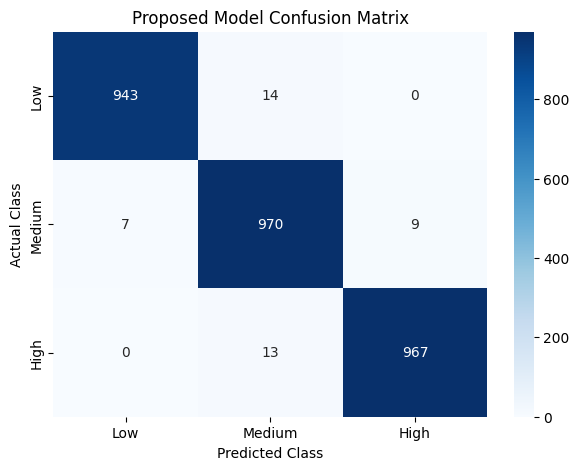

In [ ]:
labels = ["Low", "Medium", "High"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Proposed Model Confusion Matrix")

plt.show()

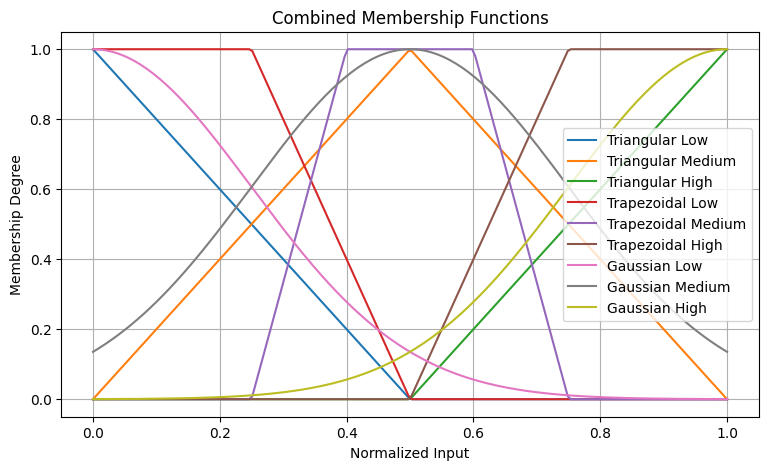

In [ ]:
x = np.linspace(0, 1, 200)

plt.figure(figsize=(9, 5))

plt.plot(
    x,
    triangular(x, -0.5, 0, 0.5),
    label="Triangular Low"
)

plt.plot(
    x,
    triangular(x, 0, 0.5, 1),
    label="Triangular Medium"
)

plt.plot(
    x,
    triangular(x, 0.5, 1, 1.5),
    label="Triangular High"
)

plt.plot(
    x,
    trapezoidal(x, -0.5, 0, 0.25, 0.5),
    label="Trapezoidal Low"
)

plt.plot(
    x,
    trapezoidal(x, 0.25, 0.4, 0.6, 0.75),
    label="Trapezoidal Medium"
)

plt.plot(
    x,
    trapezoidal(x, 0.5, 0.75, 1, 1.5),
    label="Trapezoidal High"
)

plt.plot(
    x,
    gaussian(x, 0, 0.25),
    label="Gaussian Low"
)

plt.plot(
    x,
    gaussian(x, 0.5, 0.25),
    label="Gaussian Medium"
)

plt.plot(
    x,
    gaussian(x, 1, 0.25),
    label="Gaussian High"
)

plt.xlabel("Normalized Input")
plt.ylabel("Membership Degree")

plt.title("Combined Membership Functions")

plt.legend()
plt.grid()
plt.show()